# Rekonstruktion aus unvollständigen Messungen

Ein Bild aus wenigen Fourier-Komponenten, ein Quantenzustand aus wenigen Pauli-Messungen, ein Signal aus wenigen Summen: Oft gibt es weniger Messungen als Unbekannte, und trotzdem lässt sich das Objekt zurückrechnen, wenn man etwas über seine Struktur weiß. Das Notebook zeigt das mit derselben Mathematik in drei Gebieten: Compressed Sensing an einem künstlichen Signal, ein Bild von M 87* an der echten Abdeckung des Event Horizon Telescope (öffentliche Daten von 2017) und Quantenzustände aus simulierten Messungen, zuletzt ein Bell-Zustand auf einem echten IBM-Quantencomputer. Der Code steht in [`code/`](https://github.com/deltorobarba/science/tree/main/code) (`sensing.py` für die ℓ1-Verfahren, `eht.py` für die EHT-Daten und die Bilder, `tomography.py` für die Quantenzustände, `bell.py` für den Lauf auf der Hardware); hier stehen nur die Auswahl, die Aufrufe und die Bilder.

**Der rote Faden**

Alle Schritte lösen dieselbe Gleichung $y = A\,x$ mit weniger Messungen als Unbekannten, und jedes Mal rettet ein Vorwissen über das Objekt die Rekonstruktion:

- **Schritte 1 und 2, Mathematik:** ein Signal aus zufälligen Summen. Vorwissen: Nur wenige Einträge sind nicht null ($\ell_1$-Minimierung, Basis Pursuit). Der Phasenübergang zeigt, ab wie vielen Messungen das gelingt.
- **Schritte 3 und 4, Astrophysik:** das Schwarze Loch in M 87. Sieben Radioteleskope messen einzelne Fourier-Komponenten des Bildes; Schritt 3 holt aus den echten Daten den Durchmesser des Rings und zeigt mit Closure-Phasen, wie man die Fehler der Stationen loswird; Schritt 4 rechnet das Bild zurück. Vorwissen: Helligkeit ist nie negativ, und wenige Pixel sind hell. Es ist dieselbe $\ell_1$-Rechnung wie in Schritt 1, nur mit einer Fourier-Matrix statt Zufallszahlen.
- **Schritte 5 und 6, Quantenphysik (simuliert):** ein Quantenzustand aus wenigen Pauli-Messungen. Vorwissen: Rang 1, also viele Eigenwerte null statt vieler Einträge null. Die Classical Shadows zeigen, dass man für einzelne Eigenschaften nicht den ganzen Zustand braucht.
- **Schritte 7 und 8, Quantenhardware (echt):** ein verschränkter Bell-Zustand auf einem IBM-Quantencomputer. Eine Messbasis lässt die Verschränkung offen ($m < n$ wie in Schritt 1), neun Basen entscheiden sie; die Eichung der Auslese ist ein zweites $y = A\,x$, gelöst mit der Bedingung $x \ge 0$ wie beim Bild in Schritt 4.
- **Schritt 9, Ausblick KI (noch ohne Code):** Einen LLM-Judge zu eichen, der Antworten von KI-Agenten bewertet, ist dieselbe Konfusionsmatrix wie in Schritt 8.

Die gemeinsame Antwort auf die Frage „wie viele Messungen?“: etwas mehr, als die Struktur Freiheitsgrade hat, aber weit weniger, als das Objekt Zahlen hat.

**Einführung: weniger Gleichungen als Unbekannte**

Ein kleines Beispiel zuerst. Gesucht sind drei Zahlen, gemessen werden nur zwei Summen: $x_1 + x_2 = 1$ und $x_2 + x_3 = 1$. Jedes $x = (1-t,\ t,\ 1-t)$ erfüllt beide, es gibt unendlich viele Lösungen. Die übliche Wahl ist die kürzeste, mit der kleinsten Norm $\lVert x\rVert_2$ (Pseudoinverse, kleinste Quadrate): $(\tfrac13, \tfrac23, \tfrac13)$. Sie verteilt den Wert auf alle Einträge. Weiß man aber, dass nur ein Eintrag nicht null ist, bleibt genau $(0, 1, 0)$. Diese Lösung findet man ohne Suchen: Sie hat die kleinste Betragssumme $\lVert x\rVert_1 = \vert 1-t\vert + \vert t\vert + \vert 1-t\vert$, die für $0 \le t \le 1$ gleich $2 - t$ ist und bei $t = 1$ am kleinsten wird.

Allgemein ist ein Objekt $x$ mit $n$ Zahlen gesucht (Pixel eines Bildes, Einträge einer Matrix), gemessen werden $m < n$ lineare Kombinationen mit Rauschen:

$$y = A\,x + \varepsilon, \qquad A \in \mathbb{R}^{m \times n}.$$

Die Lösungen von $A x = y$ bilden einen Raum mit $n - m$ Dimensionen. Welche man nimmt, entscheidet das Vorwissen über $x$, in der Sprache des Machine Learning der Prior oder Regularisierer:

- **Kleinste Energie**, $\hat x = A^{+} y$: die Baseline. Was nicht gemessen wurde, wird mit null gefüllt, und das Objekt verschmiert.
- **Dünnbesetzt**: $\min \lVert x\rVert_1$ unter $A x = y$ (Basis Pursuit), bei Rauschen $\min_x \tfrac12 \lVert A x - y\rVert_2^2 + \lambda \lVert x\rVert_1$ (LASSO). Die $\ell_1$-Kugel hat Ecken auf den Achsen, und der Lösungsraum berührt sie meist zuerst in einer Ecke, also in einem Punkt mit vielen Nullen (Bild in Schritt 1).
- **Niedriger Rang** bei Matrizen: Ein reiner Quantenzustand $\rho = \vert\psi\rangle\langle\psi\vert$ hat Rang 1. Statt vieler Nullen in $x$ hat $\rho$ viele Eigenwerte null.

Wie viele Messungen braucht man? Nicht $n$, sondern etwas mehr, als die Struktur Freiheitsgrade hat. Ein Signal mit $k$ von $n$ Einträgen ungleich null hat $k$ Werte und eine von $\binom{n}{k}$ möglichen Lagen, das sind etwa $k \log(n/k)$ Bits. Für zufällige Messmatrizen genügen tatsächlich $m \approx C\,k \log(n/k)$ Messungen (Candès, Romberg und Tao; Donoho; beide 2006). Die Beispiele des Notebooks und was im Lauf gereicht hat:

| Gebiet (Schritt) | Objekt | Messung | Vorwissen | Was gereicht hat |
|---|---|---|---|---|
| Mathematik (1, 2) | Signal mit 200 Zahlen | zufällige Summen | 8 Einträge ungleich null | 40 Summen (exakt) |
| Astrophysik (3, 4) | Bild von M 87*, 4096 Pixel | Fourier-Komponenten an 21 Basislinien | Helligkeit ≥ 0, wenige helle Pixel | 111 Fourier-Punkte einer Nacht (Korrelation 0.94) |
| Quantenphysik (5) | 5 Qubits, 1023 Pauli-Erwartungswerte | einzelne Erwartungswerte | Rang 1, also 62 Parameter | 250 Erwartungswerte (Fidelity 1.00) |
| Quantenphysik (6) | 10 Qubits, über eine Million Erwartungswerte | zufällige Einzel-Qubit-Messungen | nur einige Eigenschaften gesucht | 2000 Schnappschüsse für 45 Korrelationen (Fehler 0.05) |
| Quantenhardware (7, 8) | Bell-Zustand aus 2 Qubits auf ibm_aachen, 15 Pauli-Werte | eine Messbasis (3 Werte) oder neun Basen | physikalischer Zustand, Auslese geeicht | Fidelity 0.992 aus neun Basen nach Eichung der Auslese (roh 0.955) |

In den ersten drei Zeilen braucht man ein kleines Vielfaches der Freiheitsgrade, in der letzten hängt die Zahl der Messungen nur von der Frage ab.

In [1]:
import sys
import urllib.request
from pathlib import Path

CODE = Path.cwd() / "code"
if "google.colab" in sys.modules and not CODE.exists():      # in Colab den Code aus dem Repository holen
    CODE.mkdir()
    for f in ["sensing.py", "eht.py", "tomography.py", "bell.py"]:
        urllib.request.urlretrieve(f"https://raw.githubusercontent.com/deltorobarba/science/main/code/{f}", CODE / f)
sys.path.insert(0, str(CODE))      # Ordner "code" direkt importieren ("code" ist auch ein Modul der Standardbibliothek)

import sensing, eht, tomography, bell
DATA = Path.cwd() / "data" / "reconstruction"          # Cache für die EHT-Dateien

**1. Ein dünnbesetztes Signal aus zu wenigen Summen**

Ein Signal mit $n = 200$ Einträgen, von denen nur $k = 8$ nicht null sind, wird mit $m = 60$ zufälligen Summen gemessen (Gauß-Matrix $A$, ohne Rauschen). Zurückgerechnet wird zweimal: mit der kleinsten $\ell_2$-Norm über die Pseudoinverse (`sensing.min_norm`) und mit der kleinsten $\ell_1$-Norm als lineares Programm (`sensing.basis_pursuit`, scipy mit HiGHS). Links steht dasselbe in zwei Dimensionen: Eine Messung $0.4\,x_1 + x_2 = 1$ lässt eine ganze Gerade von Lösungen offen.

Links berührt die Gerade der Lösungen die kleinste $\ell_2$-Kugel (Kreis) in $(0.34, 0.86)$, einem Punkt mit zwei Einträgen ungleich null, und die kleinste $\ell_1$-Kugel (Raute) in ihrer Ecke $(0, 1)$. Rechts dasselbe in 200 Dimensionen: Die $\ell_2$-Lösung erfüllt alle 60 Messungen, verteilt aber kleine Werte auf alle 200 Einträge und trifft die wahren Werte kaum (relativer Fehler 87.3 %). Die $\ell_1$-Lösung findet genau die 8 Einträge (Fehler 0.0 %). Mit `M = 40` gelingt das noch, mit `M = 30` nicht mehr (Fehler 42 %); wo die Grenze liegt, zeigt Schritt 2.

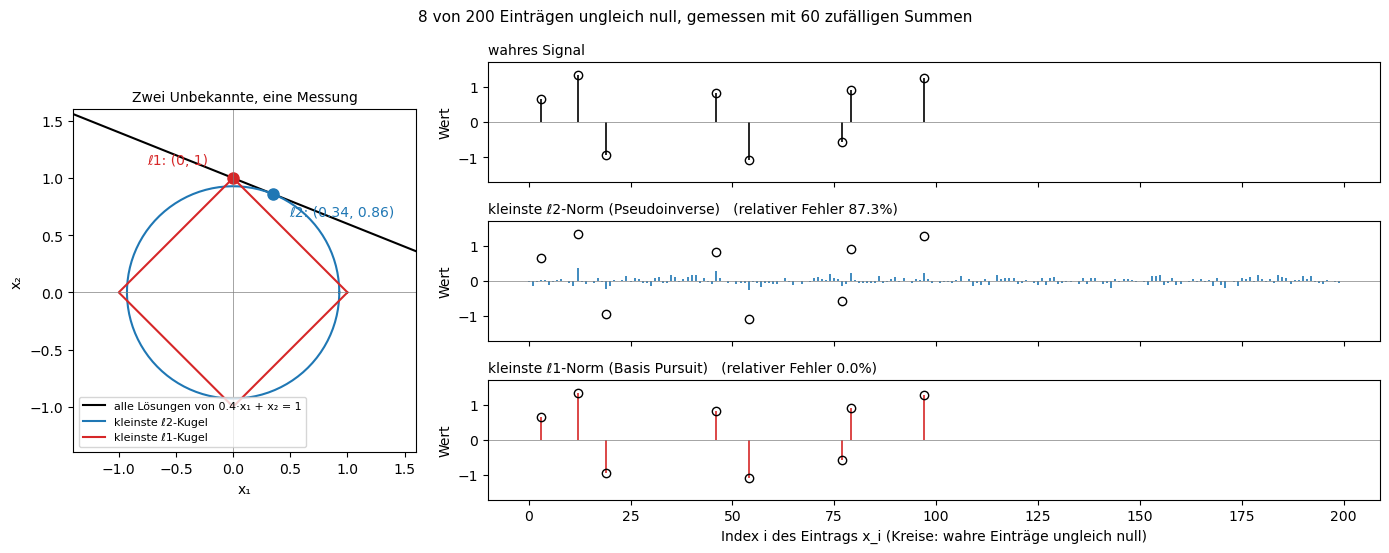

In [2]:
N, K, M = 200, 8, 60          # Unbekannte, Einträge ungleich null, Messungen
A, x, y = sensing.problem(N, K, M, seed=1)
estimates = {"kleinste ℓ2-Norm (Pseudoinverse)": sensing.min_norm(A, y),
             "kleinste ℓ1-Norm (Basis Pursuit)": sensing.basis_pursuit(A, y)}
sensing.plot_recovery(x, estimates, f"{K} von {N} Einträgen ungleich null, gemessen mit {M} zufälligen Summen")

**2. Wie viele Messungen? Der Phasenübergang**

Für $n = 100$ Unbekannte und $k = 5$, 10 und 20 Einträge ungleich null wird die Zahl der Messungen $m$ von 4 bis 100 erhöht, mit je 25 zufälligen Problemen, und gezählt, wie oft Basis Pursuit das Signal exakt findet (relativer Fehler unter $10^{-4}$). Das ist die Frage des Notebooks in ihrer einfachsten Form: Ab wie vielen Messungen reicht die Information?

Der Übergang ist scharf: Unterhalb einer Schwelle gelingt fast nichts, wenige Messungen darüber fast alles. Die Hälfte der Versuche gelingt ab etwa 19, 32 und 52 Messungen, also beim 3.9-, 3.2- und 2.6-Fachen von $k$ und weit unter $n = 100$. Je dünner das Signal, desto größer der Faktor, ähnlich wie $\ln(n/k)$ (3.0, 2.3 und 1.6) in der Formel $m \approx C\,k \log(n/k)$. Gestrichelt ist die harte Untergrenze $m = k$: Mit weniger Messungen als unbekannten Werten geht es auch dann nicht, wenn man weiß, wo die Einträge liegen.

k =  5: Hälfte exakt ab m ≈ 19 Messungen = 3.9 · k  (ln(n/k) = 3.0)
k = 10: Hälfte exakt ab m ≈ 32 Messungen = 3.2 · k  (ln(n/k) = 2.3)
k = 20: Hälfte exakt ab m ≈ 52 Messungen = 2.6 · k  (ln(n/k) = 1.6)


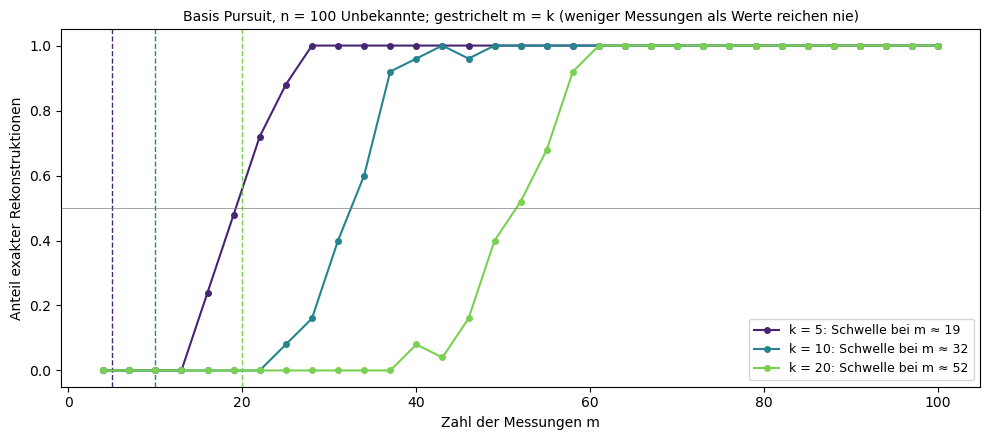

In [3]:
N, KS, TRIALS = 100, [5, 10, 20], 25     # Unbekannte, Einträge ungleich null, Versuche je Punkt
MS = list(range(4, N + 1, 3))           # Zahl der Messungen
rate, m50 = sensing.phase_transition(N, KS, MS, trials=TRIALS)
sensing.plot_transition(N, KS, MS, rate, m50)

**3. Das Schwarze Loch in M 87: was das Event Horizon Telescope misst**

Das Event Horizon Telescope (EHT) schaltet Radioteleskope auf vier Kontinenten zu einem Teleskop von der Größe der Erde zusammen. Es macht dabei kein Foto: Jedes Paar von Teleskopen misst nur eine einzige Fourier-Komponente des Himmelsbildes, und die Erdrotation verschiebt diese Komponente im Lauf der Nacht. In der Sprache der Einführung ist das $y = A\,x$: $x$ ist das Bild, $A$ die Fourier-Transformation, aber nur an den gemessenen Punkten. Dieser Schritt lädt die echten, öffentlichen Messwerte von M 87* aus vier Nächten im April 2017 (`eht.load`) und holt aus ihnen schon ohne Bild zwei Dinge heraus: den Durchmesser des Rings, mit einem Modell aus nur drei Zahlen (`eht.fit_ring`), und mit Closure-Phasen eine Aussage über die Form, die die Fehler der Stationen übersteht (`eht.plot_closure`). Das Bild selbst entsteht erst in Schritt 4.

**Begriffe**
- **Visibility** $V(u, v)$: der komplexe Messwert eines Teleskop-Paars, eine Fourier-Komponente des Bildes $I(l, m)$, also $V(u, v) = \sum_{l,m} I(l, m)\, e^{-2\pi i (u l + v m)}$. Ihr Betrag heißt Amplitude, ihr Winkel Phase.
- **Basislinie:** die Verbindung zweier Teleskope, von der Quelle aus gesehen und in Wellenlängen gemessen ($u$, $v$). 1 Gλ sind eine Milliarde Wellenlängen, bei 1.3 mm etwa 1300 km. Lange Basislinien sehen feine Strukturen.
- **(u,v)-Abdeckung:** alle gemessenen Punkte der Fourier-Ebene; je lückenhafter, desto schwerer die Rekonstruktion.
- **Ringmodell:** Die Fourier-Transformierte eines dünnen Rings ist die Bessel-Funktion $J_0$. Ihre Amplitude fällt bei einer bestimmten Länge der Basislinie auf null, und diese Stelle verrät den Durchmesser.
- **Closure-Phase:** die Summe der Phasen um ein Dreieck von Stationen, hier ALMA–SMT–LMT. Die Atmosphäre über jeder Station verschiebt die Phase um einen unbekannten Betrag; im Dreieck kommt jede Station einmal mit Plus und einmal mit Minus vor, und ihr Fehler fällt heraus. Ein punktsymmetrisches Bild hätte die Closure-Phase 0° oder 180°.
- **µas:** Mikrobogensekunde, ein Millionstel einer Bogensekunde; 40 µas ist ungefähr ein Tennisball auf dem Mond.

Die Ausgabe zählt 51 119 Visibilities auf 21 Basislinien zwischen 7 Stationen. Die längste Basislinie hat 8.33 Gλ, bei 1.3 mm Wellenlänge rund 11 000 km, das gibt eine Auflösung von etwa 25 µas. Links sieht man, wie dünn die Fourier-Ebene besetzt ist: Jede Basislinie zieht durch die Erdrotation einen Bogen, dazwischen bleiben große Lücken. Rechts fällt die Amplitude mit der Länge der Basislinie, geht bei 3.60 Gλ fast auf null und steigt danach wieder an, wie die Bessel-Funktion eines Rings. Die wenigen Punkte nahe 0 Gλ (Stationen am selben Ort) liegen höher, weil sie auch den Jet sehen; sie bleiben im Fit weg. Das Modell mit drei Zahlen ergibt 43.8 µas Durchmesser (die EHT-Kollaboration gibt 42 ± 3 µas an). Das untere Bild zeigt, warum man die Phasen nicht direkt verwenden kann: Die Phase der Basislinie ALMA–SMT dreht sich in der Nacht des 5. April um mehr als 200° und springt über ±180°, die Closure-Phase des Dreiecks bleibt dagegen zwischen etwa +30° und +80°, im Mittel +52° ± 20°, und liegt in allen vier Nächten bei +47° bis +58°. Sie ist weder 0° noch 180°, das Bild ist also nicht punktsymmetrisch, passend zur helleren Südseite des veröffentlichten Rings. Für den Durchmesser reichen die Messungen also; für ein Bild mit 4096 Pixeln fehlen die meisten Fourier-Komponenten, und wie man es trotzdem bekommt, zeigt Schritt 4.

51 119 Visibilities aus 8 Dateien, 21 Basislinien zwischen 7 Stationen
Längste Basislinie 8.33 Gλ, also Auflösung λ/B ≈ 25 µas


Ringmodell an 45 623 Amplituden: Durchmesser 43.8 µas, Breite 3.3 µas, Fluss 0.30 Jy; erste Nullstelle bei 3.60 Gλ


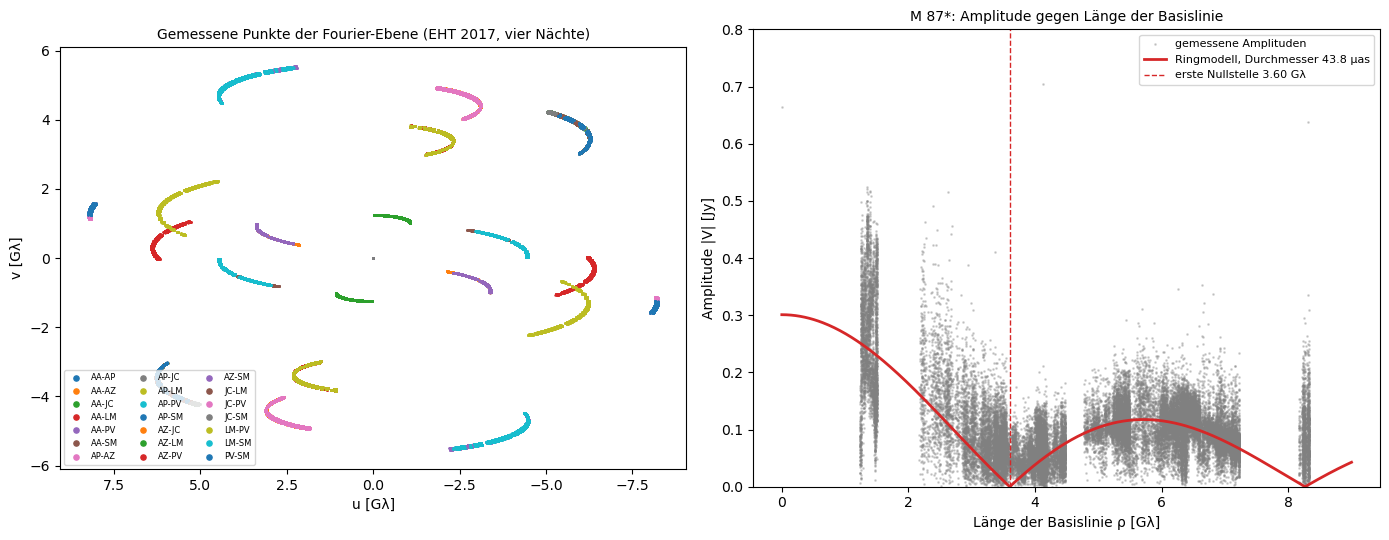

Dreieck ALMA–SMT–LMT, Band lo: Phase der Basislinie ALMA–SMT gegen Closure-Phase
    5. April (509 Zeitpunkte): Phase +136.4° ±  73.6°,  Closure-Phase +51.8° ± 20.2°
    6. April (576 Zeitpunkte): Phase -178.8° ±  62.9°,  Closure-Phase +58.4° ± 18.4°
   10. April (186 Zeitpunkte): Phase +159.7° ±  60.0°,  Closure-Phase +46.6° ± 31.2°
   11. April (529 Zeitpunkte): Phase +164.2° ±  70.9°,  Closure-Phase +48.4° ± 20.0°


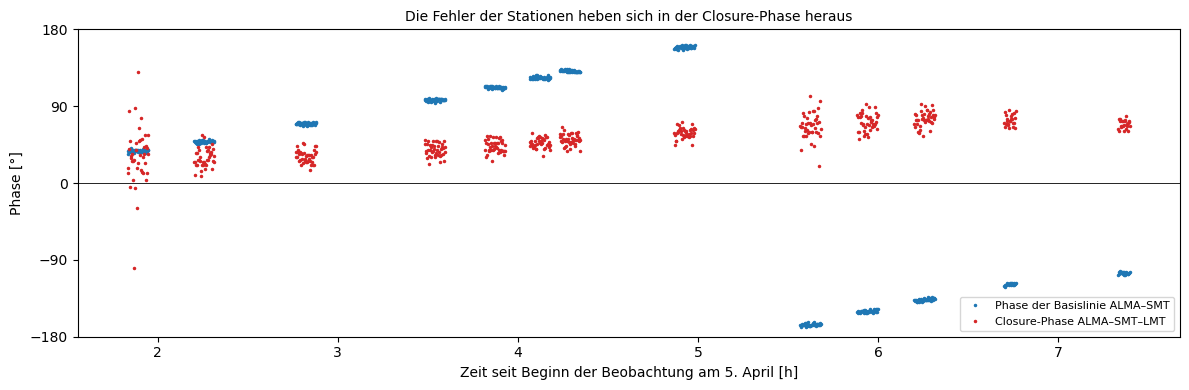

{'095': {'t': array([1.83333333, 1.83611111, 1.83888889, 1.84166667, 1.84444444,
         1.84722222, 1.85      , 1.85277778, 1.85555556, 1.85833333,
         1.86111111, 1.86388889, 1.86666667, 1.86944444, 1.87222222,
         1.875     , 1.87777778, 1.88055556, 1.88333333, 1.88611111,
         1.88888889, 1.89166667, 1.89444444, 1.89722222, 1.9       ,
         1.90277778, 1.90555556, 1.90833333, 1.91111111, 1.91388889,
         1.91666667, 1.91944444, 1.92222222, 1.925     , 1.92777778,
         1.93055556, 1.93333333, 1.93611111, 1.93888889, 1.94166667,
         1.94444444, 1.94722222, 2.20277778, 2.20555556, 2.20833333,
         2.21111111, 2.21388889, 2.21666667, 2.21944444, 2.22222222,
         2.225     , 2.22777778, 2.23055556, 2.23333333, 2.23611111,
         2.23888889, 2.24166667, 2.24444444, 2.24722222, 2.25      ,
         2.25277778, 2.25555556, 2.25833333, 2.26111111, 2.26388889,
         2.26666667, 2.26944444, 2.27222222, 2.275     , 2.27777778,
         2.28055556, 2

In [4]:
df = eht.load(DATA / "eht")       # 8 Dateien, zusammen etwa 4 MB, beim ersten Lauf aus dem Internet
fit = eht.fit_ring(df)            # Ringmodell an die Amplituden auf Basislinien über 1 Gλ
eht.plot_data(df, fit)
TRIANGLE = ("AA", "AZ", "LM")     # ALMA (Chile), SMT (Arizona), LMT (Mexiko)
eht.plot_closure(df, TRIANGLE)

**4. Das Bild des Schwarzen Lochs: aus wenigen Fourier-Punkten zurückgerechnet**

Hier entsteht das Bild zu Schritt 3, mit einem Umweg. Für ein Bild aus den echten Daten bräuchte man auch die Phasen der Visibilities, und die sind, wie Schritt 3 gezeigt hat, durch die Stationen verfälscht. Die EHT-Kollaboration rechnet deshalb mit Amplituden und Closure-Phasen und gleicht die Stationen in mehreren Durchgängen ab (Selbstkalibrierung); das führt hier zu weit. Deshalb ein kontrollierter Test: Ein Modellbild, ein Ring mit dem Durchmesser aus Schritt 3 und wie M 87* im Süden heller, wird an genau den 1071 Fourier-Punkten „gemessen“, die das EHT 2017 hatte (über 10 Minuten gemittelt), mit 10 mJy Rauschen je Punkt, und dann auf drei Arten zurückgerechnet. Weil das wahre Bild bekannt ist, lässt sich jede Methode bewerten. Die zweite Reihe wiederholt die beste Methode mit weniger Messungen: ohne die Stationen eines Standorts oder mit nur einer Nacht.

**Begriffe**
- **Dirty Image:** alle gemessenen Fourier-Komponenten zurücktransformiert, die fehlenden auf null gesetzt; das ist die $\ell_2$-Baseline der Einführung. Es zeigt das wahre Bild, verschmiert mit dem Muster der Lücken (dem Dirty Beam).
- **CLEAN** (Högbom 1974, das klassische Verfahren der Radioastronomie): sucht im Dirty Image die hellste Stelle, nimmt dort eine Punktquelle an, zieht deren Muster ab und wiederholt das; zuletzt werden die Punkte auf die übliche Auflösung von 20 µas verschmiert. Eine gierige Suche nach wenigen Punkten, also Dünnbesetztheit wie in Schritt 1.
- **ℓ1 mit Positivität:** das LASSO der Einführung, $\min_x \tfrac12 \lVert A x - y\rVert_2^2 + \lambda \lVert x\rVert_1$ mit $x \ge 0$, gelöst mit dem Verfahren FISTA (`eht.reconstruct`).
- **Kreuzkorrelation:** wie ähnlich zwei Bilder sind; 1 heißt gleich bis auf die Helligkeit, 0 nichts gemeinsam.
- **Auflösung:** Ein Teleskop der Größe $B$ trennt Strukturen bis etwa $\lambda/B$, beim EHT 25 µas. Feinere Details kann nur ein Vorwissen ergänzen.

Das Dirty Image zeigt vor allem das Muster der Lücken (Kreuzkorrelation mit dem wahren Bild 0.37). CLEAN findet den Ring mit der hellen Südseite, aber verschmiert auf die übliche Auflösung von 20 µas (0.72, genauso viel wie das verschmierte wahre Bild). ℓ1 mit Positivität gibt den Ring fast unverändert zurück (0.98), also schärfer, als die nominelle Auflösung von 25 µas erlaubt: Schon „keine negative Helligkeit“ ist ein starkes Vorwissen. Welche Messungen dafür nötig sind, zeigt die zweite Reihe. Ohne Chile (ALMA und APEX) zerfällt der Ring in zwei Flecken (0.70), ohne Arizona in Bögen (0.74), ohne Mexiko bleibt er mit Artefakten erkennbar (0.86). Die Nacht des 10. April allein, mit nur 111 Fourier-Punkten, reicht dagegen fast (0.94). Es kommt also weniger auf die Zahl der Punkte an als darauf, welche Richtungen und Längen der Fourier-Ebene sie abdecken. Die Simulation ist günstig: perfekte Phasen, gleiches Rauschen an allen Stationen und ein einfaches Bild. Das Bild, das die EHT-Kollaboration 2019 veröffentlicht hat, kam aus den echten Daten über Closure-Phasen wie in Schritt 3 und den Vergleich mehrerer Verfahren.

Bild 64 × 64 = 4096 Pixel zu 2.5 µas; Rauschen 10 mJy je Punkt
Kreuzkorrelation mit dem wahren Bild (1 = gleich):
  Dirty Image              0.37   (1071 gemittelte Fourier-Punkte)
  CLEAN (20 µas)           0.72   (1071 gemittelte Fourier-Punkte)
  ℓ1 + Helligkeit ≥ 0      0.98   (1071 gemittelte Fourier-Punkte)
  ℓ1 ohne Chile            0.70   (434 gemittelte Fourier-Punkte)
  ℓ1 ohne Arizona          0.74   (738 gemittelte Fourier-Punkte)
  ℓ1 ohne Mexiko           0.86   (691 gemittelte Fourier-Punkte)
  ℓ1, nur 10. April        0.94   (111 gemittelte Fourier-Punkte)
  zum Vergleich: wahres Bild mit 20 µas verschmiert 0.72


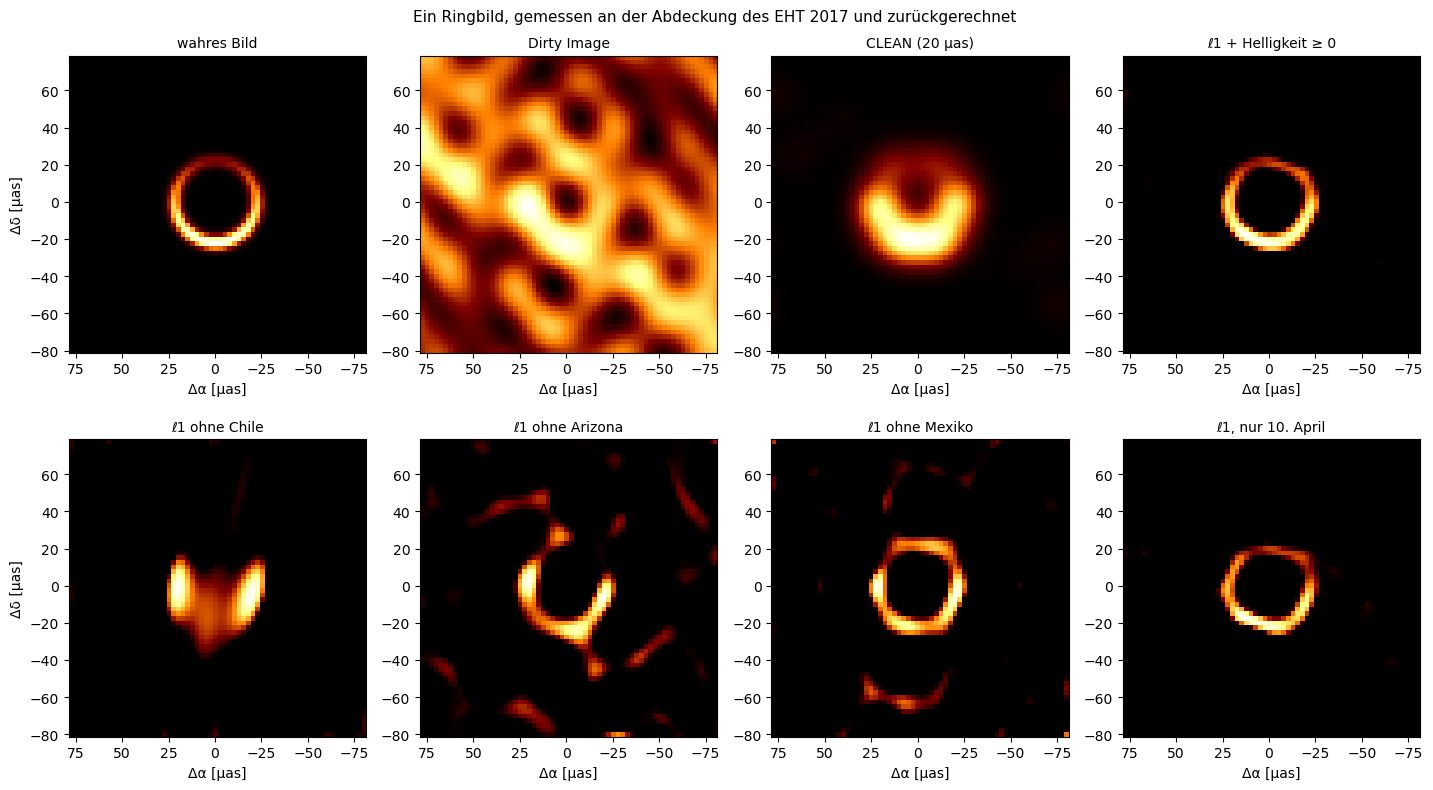

In [5]:
NOISE_JY = 0.01          # Rauschen je gemittelter Visibility (10 Minuten)
LAMBDA = 0.01            # Gewicht der ℓ1-Norm, relativ zum größten Wert von Aᵀy
NIGHT = "100"            # eine Nacht allein: "095", "096", "100" oder "101"
truth = eht.crescent(d_uas=fit["d"], width_uas=6, flux=0.6, contrast=0.6)     # Ring, im Süden heller
F, oben, unten = eht.compare(df, truth, NOISE_JY, LAMBDA, drop=("Chile", "Arizona", "Mexiko"), night=NIGHT)
eht.plot_images(F, [oben, unten], "Ein Ringbild, gemessen an der Abdeckung des EHT 2017 und zurückgerechnet")

**5. Ein Quantenzustand aus wenigen Pauli-Messungen**

Ein Zustand aus $q = 5$ Qubits ist durch $4^5 - 1 = 1023$ Erwartungswerte von Pauli-Strings wie $\langle XZIYZ\rangle$ bestimmt: $\rho = \tfrac{1}{d}\big(I + \sum_P \langle P\rangle\, P\big)$ mit $d = 2^q = 32$. Volle Tomographie misst alle. Hier wird nur eine zufällige Auswahl von $m$ Strings gemessen, jeder mit 1000 Schüssen, für zufällige reine Zustände (Mittel über 5). Zurückgerechnet wird linear, mit den fehlenden Erwartungswerten als null (das Gegenstück zum Dirty Image), und mit der Annahme Rang 1 (`tomography.low_rank`: Gradientenschritt, dann auf den größten Eigenvektor projizieren). Ein reiner Zustand hat nur $2d - 2 = 62$ reelle Parameter.

**Begriffe**
- **Pauli-String:** ein Produkt aus I, X, Y oder Z, eines je Qubit, etwa XZIYZ. Sein Erwartungswert liegt zwischen −1 und +1 und wird mit vielen Schüssen geschätzt.
- **Schuss:** eine einzelne Messung mit Ergebnis +1 oder −1; aus 1000 Schüssen wird ein Erwartungswert auf etwa ±0.03 genau.
- **Fidelity:** $\langle\psi\vert\hat\rho\vert\psi\rangle$, die Wahrscheinlichkeit, dass der rekonstruierte Zustand einen Test auf den wahren besteht; 1 heißt gleich.
- **Rang 1:** Ein reiner Zustand $\vert\psi\rangle\langle\psi\vert$ hat nur einen Eigenwert ungleich null, so wie ein dünnbesetztes Signal nur wenige Einträge ungleich null hat.

Die lineare Rekonstruktion wächst gerade mit dem gemessenen Anteil: Bei 400 von 1023 Strings hat sie eine Fidelity von 0.41, erst mit allen 1.00. Mit der Annahme Rang 1 hilft unter 150 Strings nichts, dann springt die Fidelity von 0.20 bei 150 über 0.76 bei 200 auf 1.00 bei 250 Strings, ein Phasenübergang wie in Schritt 2. Die Schwelle um 200 Strings liegt beim Drei- bis Vierfachen der 62 Parameter, ähnlich wie das 2.6- bis 3.9-Fache von $k$ in Schritt 2, und bei einem Fünftel aller Strings. Ein Lauf mit 4 Qubits (255 Strings, 30 Parameter) hatte die Schwelle zwischen 50 und 80 Strings. Das ist Compressed Sensing für Matrizen (Gross und andere, 2010): Für Rang $r$ genügen etwa $r\,d \log^2 d$ statt $d^2$ Messungen, und der Vorteil wächst mit der Zahl der Qubits.

5 Qubits: Dichtematrix mit 1023 reellen Zahlen, reiner Zustand mit 62 Parametern
  m =   20 Pauli-Strings (  2%): Fidelity linear 0.05, mit Rang 1 0.02
  m =   40 Pauli-Strings (  4%): Fidelity linear 0.07, mit Rang 1 0.03
  m =   62 Pauli-Strings (  6%): Fidelity linear 0.09, mit Rang 1 0.01
  m =  100 Pauli-Strings ( 10%): Fidelity linear 0.13, mit Rang 1 0.10
  m =  150 Pauli-Strings ( 15%): Fidelity linear 0.17, mit Rang 1 0.20
  m =  200 Pauli-Strings ( 20%): Fidelity linear 0.23, mit Rang 1 0.76
  m =  250 Pauli-Strings ( 24%): Fidelity linear 0.26, mit Rang 1 1.00
  m =  300 Pauli-Strings ( 29%): Fidelity linear 0.31, mit Rang 1 1.00
  m =  400 Pauli-Strings ( 39%): Fidelity linear 0.41, mit Rang 1 1.00
  m =  600 Pauli-Strings ( 59%): Fidelity linear 0.60, mit Rang 1 1.00
  m = 1023 Pauli-Strings (100%): Fidelity linear 1.00, mit Rang 1 1.00


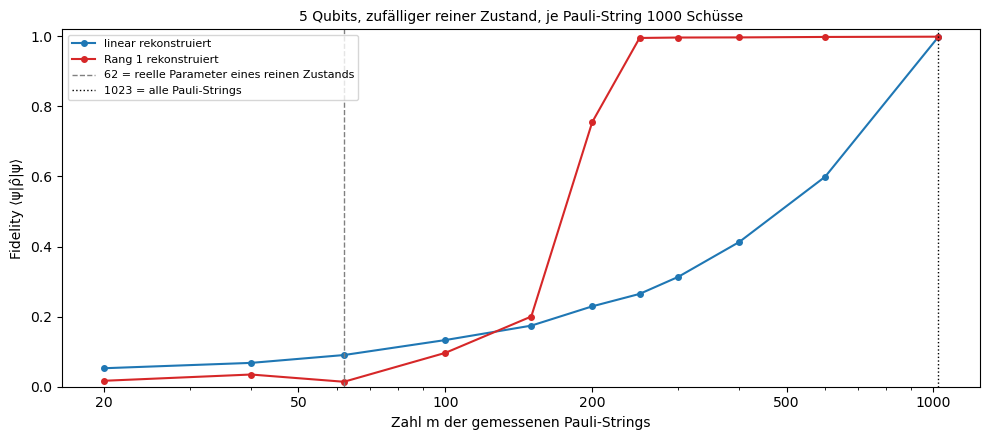

In [6]:
QUBITS, SHOTS = 5, 1000                                       # 5 Qubits: 1023 Pauli-Strings
MS = [20, 40, 62, 100, 150, 200, 250, 300, 400, 600, 1023]    # Zahl der gemessenen Strings
scan = tomography.tomography_scan(QUBITS, MS, SHOTS, trials=5)
tomography.plot_tomography(QUBITS, MS, scan, SHOTS)

**6. Classical Shadows: Eigenschaften statt Zustand**

Bei 10 Qubits hat die Dichtematrix schon $4^{10} - 1 \approx 10^6$ Pauli-Erwartungswerte, Tomographie ist aussichtslos. Oft will man aber nur einige Eigenschaften wissen, etwa Korrelationen. Classical Shadows (Huang, Kueng und Preskill, 2020) messen jedes Qubit in einer zufälligen Basis X, Y oder Z und speichern Basis und Ergebnis als Schnappschuss. Ein Pauli-String auf $w$ Qubits wird aus den Schnappschüssen geschätzt, in denen alle $w$ Basen passen (ein Anteil von $3^{-w}$), mit dem Faktor $3^w$ als Ausgleich. Simuliert wird der Grundzustand einer Ising-Kette aus 10 Qubits am kritischen Punkt $h = J$, exakt berechnet mit scipy (`tomography.ising_ground_state`), mit 20 000 Schnappschüssen.

**Begriffe**
- **Schnappschuss:** ein Durchlauf, in dem jedes Qubit in einer zufällig gewählten Basis X, Y oder Z gemessen wird; gespeichert werden die Basen und die Ergebnisse.
- **Gewicht** $w$: auf wie vielen Qubits ein Pauli-String nicht I ist; $\langle Z_i Z_j\rangle$ hat $w = 2$.
- **Ising-Kette:** 10 Spins in einer Reihe, die sich mit der Stärke $J$ gleich ausrichten wollen, gegen ein Querfeld $h$. Bei $h = J$ (kritischer Punkt) geht die Ordnung gerade verloren, und die Korrelationen fallen mit dem Abstand nur langsam.

Links liegen aus 2000 Schnappschüssen alle 45 Korrelationen $\langle Z_i Z_j\rangle$ im Mittel 0.05 neben dem exakten Wert (höchstens 0.15), genug, um den Abfall mit dem Abstand zu sehen. Rechts fällt der Fehler wie $1/\sqrt N$ und wächst mit dem Gewicht wie $\sqrt{3^w}$, so wie die gestrichelte Theorie $\sqrt{2/\pi}\,\sqrt{3^w/N}$ (der Faktor $\sqrt{2/\pi} \approx 0.8$ ist der mittlere Betrag einer Normalverteilung mit Streuung 1). Bei 10 000 Schnappschüssen sind es 0.013 für $w = 1$ und 0.067 für $w = 4$. Die Zahl der Qubits kommt in der Formel nicht vor: Wie viele Messungen man braucht, hängt hier von der Frage ab (Gewicht, Genauigkeit und laut Theorie nur logarithmisch von der Zahl der gesuchten Eigenschaften), nicht von der Größe des Zustands. Mit `H = 0.5` (geordnete Phase, ausprobiert) folgen die Fehler derselben Kurve.

10 Qubits: Der Zustand hat 2^10 = 1024 Amplituden, die Dichtematrix 1 048 575 Pauli-Erwartungswerte
Aus 2000 Schnappschüssen alle 45 Korrelationen ⟨Z_i Z_j⟩: mittlerer Fehler 0.052, größter 0.152
  Gewicht 1: Fehler 0.124 (N = 100), 0.068 (N = 300), 0.039 (N = 1000), 0.022 (N = 3000), 0.013 (N = 10000);  Theorie √(2/π)·√(3^w/N) bei N = 10000: 0.014
  Gewicht 2: Fehler 0.230 (N = 100), 0.142 (N = 300), 0.073 (N = 1000), 0.043 (N = 3000), 0.022 (N = 10000);  Theorie √(2/π)·√(3^w/N) bei N = 10000: 0.024
  Gewicht 3: Fehler 0.388 (N = 100), 0.234 (N = 300), 0.138 (N = 1000), 0.075 (N = 3000), 0.036 (N = 10000);  Theorie √(2/π)·√(3^w/N) bei N = 10000: 0.041
  Gewicht 4: Fehler 0.717 (N = 100), 0.442 (N = 300), 0.263 (N = 1000), 0.123 (N = 3000), 0.067 (N = 10000);  Theorie √(2/π)·√(3^w/N) bei N = 10000: 0.072


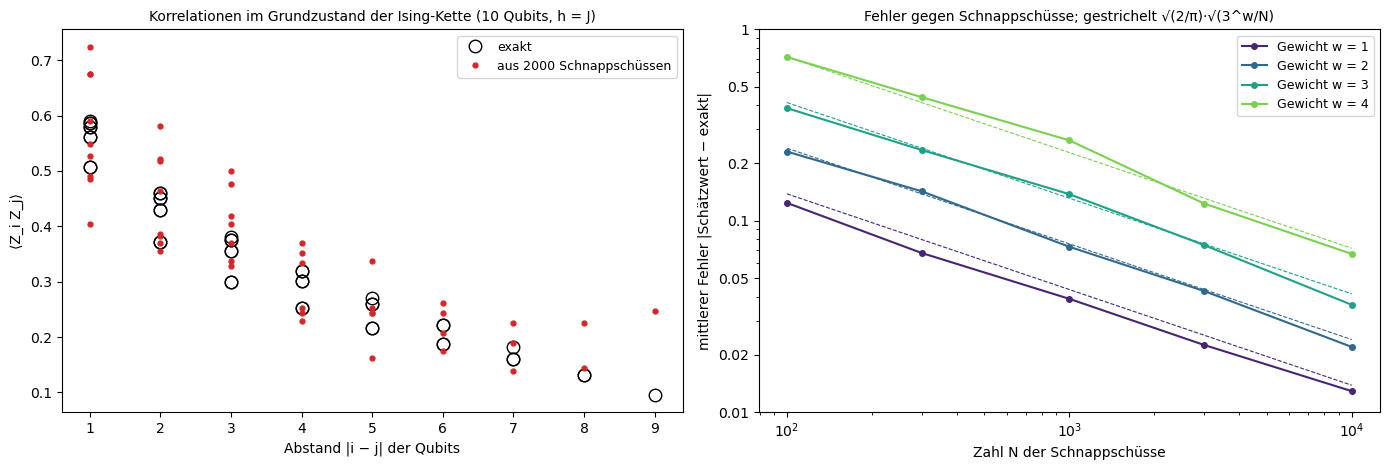

In [7]:
QUBITS, H = 10, 1.0          # Ising-Kette H = −J Σ Z_i Z_(i+1) − h Σ X_i; h = J ist der kritische Punkt
N_SHOW = 2000                # Schnappschüsse für das linke Bild
psi = tomography.ising_ground_state(QUBITS, h=H)
bases, outcomes = tomography.snapshots(psi, QUBITS, 20_000, seed=1)
zz_exact, zz_shadow, errors = tomography.shadow_study(psi, QUBITS, bases, outcomes, N_SHOW, ns=[100, 300, 1000, 3000, 10_000])

**7. Ein Bell-Zustand auf echter Hardware: was eine Messbasis verrät**

Ab hier wird nicht mehr simuliert. Zwei Qubits eines IBM-Quantencomputers werden in den Bell-Zustand |Φ⁺⟩ = (|00⟩ + |11⟩)/√2 gebracht: Ein Hadamard-Gatter macht aus Qubit 0 die Überlagerung (|0⟩ + |1⟩)/√2, ein CNOT-Gatter überträgt den Wert auf Qubit 1. Misst man beide Qubits, kommt zufällig 00 oder 11, je zur Hälfte, aber nie 01 oder 10. Dieselben Ergebnisse liefert aber auch ein klassisches Gemisch, eine Münze, die beide Qubits gemeinsam auf 00 oder auf 11 setzt. Der Unterschied, die Verschränkung, steckt in der Phase zwischen |00⟩ und |11⟩. Am 2026-09-11 lief der Schaltkreis auf `ibm_aachen` (156 Qubits, Prozessor Heron) mit 100 Messungen in der Rechenbasis (`bell.one_basis`). Ist der Zustand damit bestimmt?

**Begriffe**
- **Schuss:** ein Durchlauf aus Präparieren und Messen; er liefert zwei Bits, etwa 11. Die Ausgabe zählt, wie oft jedes Bitpaar vorkam.
- **Messbasis:** Die Hardware misst immer 0 oder 1, die Z-Basis. Für die X- oder Y-Basis dreht man jedes Qubit kurz vor der Messung (Hadamard für X, S† und Hadamard für Y).
- **Pauli-Wert** ⟨ZZ⟩: Ergebnis 0 zählt als +1, Ergebnis 1 als −1, und ⟨ZZ⟩ ist der Mittelwert des Produkts beider Qubits. +1 heißt immer gleich, −1 immer verschieden, 0 unabhängig. ⟨ZI⟩ ist der Mittelwert von Qubit 0 allein (das erste Zeichen gehört zu Qubit 0, I heißt „nicht gemessen“).
- **15 Pauli-Werte:** Ein Zustand zweier Qubits ist durch die 15 Werte ⟨AB⟩ mit A und B aus I, X, Y, Z (ohne II) vollständig bestimmt. Die Z-Basis liefert drei davon: $m = 3$ Messwerte für $n = 15$ Unbekannte, das Problem der Einführung.

Die Ausgabe zählt 96 von 100 korrelierten Ergebnissen (54-mal 11, 42-mal 00), also ⟨ZZ⟩ = +0.92 ± 0.10. Das sieht nach einem guten Bell-Zustand aus, aber die Tabelle darunter zeigt das Problem: |Φ⁺⟩, |Φ⁻⟩ und das Gemisch sagen für die drei gemessenen Werte genau dasselbe voraus (links vom Strich) und unterscheiden sich erst in ⟨XX⟩ und ⟨YY⟩. Im Bild sind die drei gemessenen Werte blaue Balken, die zwölf grau hinterlegten Spalten fehlen, und Kreise, Quadrate und Rauten sind die Vorhersagen der drei Zustände: In den weißen Spalten liegen sie übereinander. Die Verschränkung ist in der Z-Basis also unsichtbar, und die 96 % sind nur eine obere Schranke für die Fidelity. ⟨ZI⟩ = ⟨IZ⟩ = −0.12 deutet auf etwas mehr 11 als 00, liegt bei 100 Schüssen aber noch in der Streuung von ±0.10.

ibm_aachen, 2026-09-11: 100 Schüsse, beide Qubits in der Z-Basis gemessen (Ergebnis 0 oder 1)
Zählungen:  00: 42,  01: 2,  10: 2,  11: 54   →  96% korreliert (00 oder 11)
Daraus 3 von 15 Pauli-Werten (je etwa ± 0.10):  ⟨ZI⟩ = -0.12,  ⟨IZ⟩ = -0.12,  ⟨ZZ⟩ = +0.92

Was drei Zustände vorhersagen        ⟨ZI⟩  ⟨IZ⟩  ⟨ZZ⟩ │ ⟨XX⟩  ⟨YY⟩
  |Φ⁺⟩ = (|00⟩ + |11⟩)/√2              +0    +0    +1 │   +1    -1
  |Φ⁻⟩ = (|00⟩ − |11⟩)/√2              +0    +0    +1 │   -1    +1
  Gemisch ½|00⟩⟨00| + ½|11⟩⟨11|        +0    +0    +1 │   +0    +0
Links vom Strich gleich, also passen alle drei zur Messung; erst XX und YY würden sie unterscheiden.


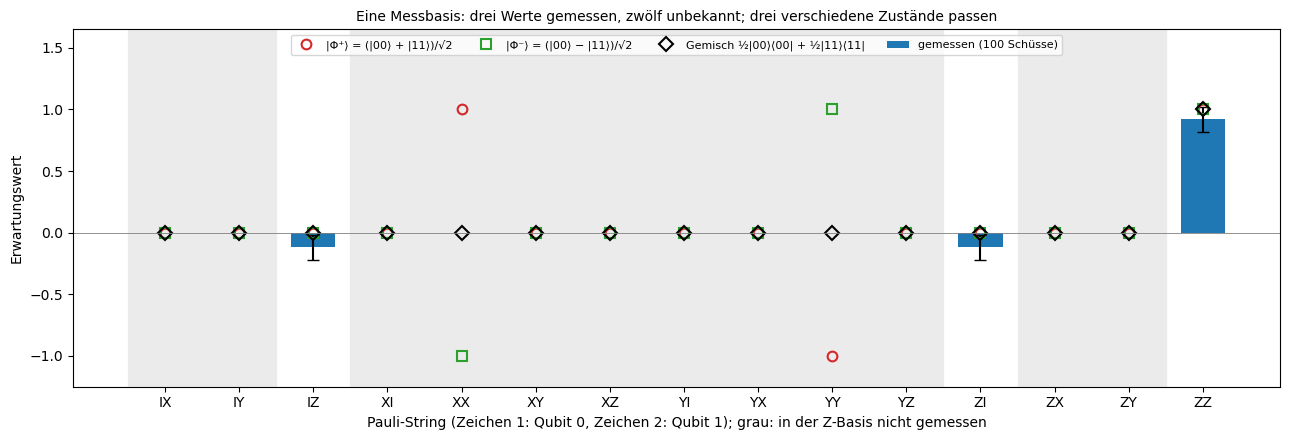

In [8]:
Z_ONLY = bell.ZZ_2026_09_11          # 100 Schüsse in der Z-Basis, ibm_aachen, 2026-09-11
E_z = bell.one_basis(Z_ONLY)

**8. Tomographie auf echter Hardware: der ganze Zustand aus neun Basen**

Am 2026-11-12 lief auf `ibm_aachen` ein Job mit 13 Schaltkreisen zu je 1000 Schüssen, alle auf denselben physikalischen Qubits 0 und 1 (`bell.run_ibm`, 6 s Rechenzeit; `RUN_ON_HARDWARE = True` wiederholt ihn in Colab mit einem eigenen IBM-Konto). Neun Schaltkreise präparieren |Φ⁺⟩ wie in Schritt 7 und drehen dann jedes Qubit in die Basis X, Y oder Z; die neun Kombinationen XX, XY, …, ZZ liefern alle 15 Pauli-Werte. Vier weitere Schaltkreise präparieren nur |00⟩, |01⟩, |10⟩ oder |11⟩ und messen sofort, um die Fehler beim Auslesen zu eichen. Die Auswertung hat drei Teile (`bell.tomography_study`). Erstens wird aus den vier Eichläufen die Konfusionsmatrix $A$ gebildet, und jede gemessene Verteilung $y$ wird zurückgerechnet, indem man $A\,x = y$ mit der Bedingung $x \ge 0$ löst, wieder ein inverses Problem wie in der Einführung. Zweitens entsteht aus den 15 Pauli-Werten die Dichtematrix, linear über $\rho = (I + \sum_P \langle P\rangle P)/4$ oder mit Maximum-Likelihood wie in Schritt 5. Drittens wird verglichen, was drei Basen allein hergeben: $F = (1 + \langle XX\rangle - \langle YY\rangle + \langle ZZ\rangle)/4$.

**So liest man die Ausgabe**
- **Konfusionsmatrix:** Spalte = präparierter Zustand, Zeile = gemessenes Ergebnis. Auf der Diagonale steht, wie oft richtig gelesen wird (97 bis 98 %), daneben die Verwechslungen: 0.018 in Spalte 01 und Zeile 11 heißt, bei |01⟩ wird Qubit 1 in 1.8 % der Fälle fälschlich als 1 gelesen.
- **roh und ohne Auslesefehler:** links direkt aus den Zählungen, rechts nach dem Zurückrechnen mit der Konfusionsmatrix.
- **Fidelity:** ⟨Φ⁺|ρ|Φ⁺⟩, die Wahrscheinlichkeit, dass der Zustand einen Test auf |Φ⁺⟩ besteht; 1 heißt perfekt, 0.25 völlig zufällig.
- **kleinster Eigenwert:** Die Eigenwerte einer Dichtematrix sind Wahrscheinlichkeiten und dürfen nicht negativ sein. Ist einer negativ, ist die Schätzung kein möglicher Zustand; Maximum-Likelihood sucht nur unter den erlaubten.
- **Reinheit** Tr ρ²: 1 für einen reinen Zustand, 0.25 für völliges Rauschen.
- **Kohärenz** Re ρ(00, 11): das Element der Dichtematrix zwischen |00⟩ und |11⟩, die Phase aus Schritt 7. Ideal 0.5, beim klassischen Gemisch 0; im Bild rechts sind es die roten Felder oben rechts und unten links.

Links im Bild liegen alle 15 Werte nahe bei |Φ⁺⟩: roh ⟨XX⟩ = +0.94, ⟨YY⟩ = −0.93 und ⟨ZZ⟩ = +0.95, alle übrigen höchstens 0.07 von null entfernt. Damit ist entschieden, was die Z-Basis in Schritt 7 offenließ: Es ist |Φ⁺⟩, weder |Φ⁻⟩ (dort wäre ⟨XX⟩ = −1) noch das Gemisch (⟨XX⟩ = ⟨YY⟩ = 0); die Kohärenz ist 0.47 statt 0. Die Konfusionsmatrix zeigt 2.3 bis 3.1 % Auslesefehler je präpariertem Zustand. Nach ihrer Korrektur steigen die drei großen Werte auf ±0.99, die Fidelity von 0.955 auf 0.992 (statistisch etwa ±0.005), die Reinheit von 0.914 auf 0.986 und die Kohärenz auf 0.49: Der größte Teil des Fehlers liegt in der Auslese, kaum im Zustand. Die lineare Inversion gibt dieselbe Fidelity, aber einen negativen Eigenwert (−0.025), also keinen möglichen Zustand; Maximum-Likelihood (rechts im Bild) bleibt erlaubt. Auch die Eichung zeigt das Muster der Einführung: Direkt invertiert gibt die Konfusionsmatrix 2 negative von 36 Wahrscheinlichkeiten, mit der Bedingung x ≥ 0 keine. Und die drei Basen XX, YY und ZZ allein geben dieselbe Fidelity wie alle neun: Für eine bestimmte Frage reichen weniger Messungen, wie bei den Shadows in Schritt 6.

ibm_aachen, 2026-11-12, Job dbqtp2kim45s738hefh0, physikalische Qubits [0, 1]: 9 Basen und 4 Kalibrierungen zu je 1000 Schüssen

Konfusionsmatrix der Auslese (Spalte: präpariert, Zeile: gemessen; Diagonale: richtig gelesen)
              präp. 00  präp. 01  präp. 10  präp. 11
  gemessen 00     0.975     0.013     0.013     0.000
  gemessen 01     0.017     0.969     0.000     0.014
  gemessen 10     0.008     0.000     0.977     0.012
  gemessen 11     0.000     0.018     0.010     0.974
  richtig gelesen: 00 97.5%, 01 96.9%, 10 97.7%, 11 97.4%

                                       roh  ohne Auslesefehler
Fidelity aus XX, YY, ZZ (direkt)     0.955               0.992   (± 0.005 aus der Zahl der Schüsse)
Fidelity, lineare Inversion          0.955               0.992   (aus allen 15 Pauli-Werten)
  kleinster Eigenwert dieser ρ      -0.012              -0.025   (negativ: kein möglicher Zustand)
Fidelity, Maximum-Likelihood         0.955               0.992   (nur erlaubte Zustände)
Rein

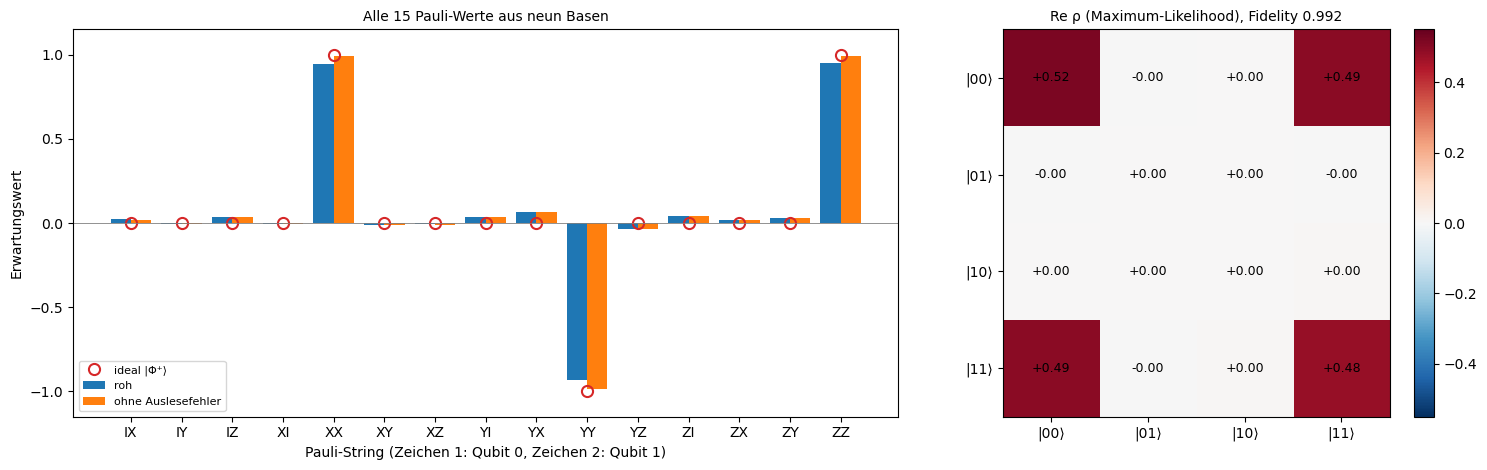

In [9]:
DATA = bell.AACHEN_2026_11_12        # 9 Basen und 4 Kalibrierungen zu je 1000 Schüssen, ibm_aachen, 2026-11-12
RUN_ON_HARDWARE = False               # True: neuer Lauf in Colab (IBM-Konto, Token im Colab-Secret "ibm-quantum")
if RUN_ON_HARDWARE and "google.colab" in sys.modules:
    import subprocess
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "qiskit", "qiskit-ibm-runtime"], check=True)
    from google.colab import userdata
    DATA = bell.run_ibm(userdata.get("ibm-quantum"), shots=1000)
results = bell.tomography_study(DATA)

**9. Ausblick: einen KI-Judge eichen wie die Auslese eines Quantencomputers**

Bei der Bewertung von KI-Agenten entscheidet oft ein Sprachmodell, ob eine Antwort richtig ist (LLM-as-a-Judge). Auch dieser Judge ist ein Messgerät mit Auslesefehlern: Er erkennt eine richtige Antwort nur mit der Trefferquote TPR und eine falsche mit der Quote TNR. Gemessen wird, bei welchem Anteil $\hat p$ der Antworten der Judge „richtig“ sagt; gesucht ist die wahre Erfolgsquote $p$ des Agenten. Das ist die Konfusionsmatrix aus Schritt 8, nur mit einem Bit statt zweien: $\hat p = \mathrm{TPR}\cdot p + (1 - \mathrm{TNR})(1 - p)$, also $p = (\hat p + \mathrm{TNR} - 1)/(\mathrm{TPR} + \mathrm{TNR} - 1)$ (Rogan und Gladen 1978, ursprünglich für medizinische Tests). Dieser Schritt ist noch ohne Code; er zeigt, wie dieselbe Rechnung in die Evaluation von KI führt.

**Begriffe**
- **Eichläufe:** Statt |00⟩ bis |11⟩ zu präparieren, nimmt man Antworten, deren Urteil Menschen festgelegt haben. Aus ihnen schätzt man TPR und TNR, so wie die Konfusionsmatrix aus den vier Kalibrier-Schaltkreisen.
- **Zahlenbeispiel:** Der Judge sagt bei 70 % der Antworten „richtig“, mit TPR = 0.90 und TNR = 0.80. Dann ist $p = (0.70 + 0.80 - 1)/(0.90 + 0.80 - 1) = 0.71$; der Agent ist etwas besser, als der Judge ihn misst.
- **Dieselbe Falle:** Liegt $\hat p$ unter $1 - \mathrm{TNR}$ oder über TPR, gibt die Formel Werte unter 0 oder über 1; die Bedingung $0 \le p \le 1$ hilft wie $x \ge 0$ in Schritt 8. Je näher TPR + TNR an 1 liegt, desto stärker wird jedes Rauschen verstärkt: Ein Judge, der nur rät, lässt sich nicht eichen.
- **Unsicherheit:** Sie kommt aus zwei Quellen, der Zahl der bewerteten Antworten und der Zahl der menschlichen Labels für TPR und TNR; oft dominieren die wenigen Labels.

Ein Code-Schritt könnte das an Daten zeigen: einen Judge mit bekannten Fehlerquoten simulieren oder echte Urteile nehmen, TPR und TNR aus wenigen hundert Labels schätzen und die korrigierte Erfolgsquote mit Konfidenzintervall neben die rohe stellen. Es ist dieselbe Lehre wie im ganzen Notebook: Erst wer das Messgerät kennt, kann vom Messwert auf das Objekt zurückrechnen.